# NganyaFlow: real Nairobi transport network analysis

A passenger needs to find a boarding point and see which routes serve it.
This notebook uses the Digital Matatus Nairobi network to study that part
of NganyaFlow. We inspect the source tables, clean stop records, check how
the tables connect, and explore the CBD network with NumPy and pandas.

We also try a small machine learning exercise: grouping nearby boarding points
to help plan observation coverage. This uses **unsupervised learning**, where
the algorithm finds groups without being given correct group labels.
A separate distance calculation demonstrates how the mobile app could rank
nearby stops.

The source is the official 2019 network release, whose service calendar ends
in 2020. It supports historical network analysis. Its static times do not
supply the dated arrival observations needed to train or score the waiting-time
QRF. The final section separates data checks, clustering scores and prediction
accuracy so each result has a clear meaning.

Run the cells in order using the project environment. If the archive is missing,
follow the download command in [the setup guide](README.md). This notebook runs
offline once the source is available and saves its own results under
`results/digital-matatus-2019/`. It does not change the other notebooks or
activate a model on the server.

## 1. Prepare the workspace

pandas handles the tables, NumPy performs the numerical calculations, and
Matplotlib draws the charts. scikit-learn supplies the clustering algorithm.
A **DataFrame** is a table; a **Series** is one column or a labelled list.
`assert` checks an assumption and stops the cell if it is false.

The package versions help someone repeat the analysis with the same tools.
No learning happens in this setup cell.

In [1]:
import hashlib
import importlib.metadata as metadata
import json
from pathlib import Path
from zipfile import ZipFile

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'server/src/nganyaflow/ml.py').is_file())
DATA = ROOT / 'server/data/external/digital-matatus-2019'
ARCHIVE = DATA / 'source/GTFS_FEED_2019.zip'
if not ARCHIVE.is_file():
    raise FileNotFoundError(
        'Run from the repository root: python server/scripts/prepare_real_dataset.py')
OUT = ROOT / 'server/notebooks/results/digital-matatus-2019'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series({name: metadata.version(name) for name in
                   ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'notebook']},
                  name='version').to_frame())

,version
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
matplotlib,3.11.2
notebook,7.6.4


## 2. Open the original archive

GTFS, short for General Transit Feed Specification, stores different parts of a
transport network in separate tables. `stops` describes locations, `routes`
describes services, `trips` describes journeys, and `stop_times` lists the
stops along those journeys. `frequencies` gives the feed's service intervals.

We read the original ZIP, rather than relying on the already prepared CSV files,
so the cleaning steps remain visible. IDs are read as text to preserve leading
zeros. The SHA256 fingerprint checks that this is the archive previously recorded
in the source manifest; it does not prove that a stop is correctly located.

In [2]:
source = json.loads((DATA / 'source.json').read_text(encoding='utf-8'))
source_hash = hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
assert source_hash == source['archive_sha256']
table_names = ['agency', 'calendar', 'calendar_dates', 'feed_info', 'frequencies',
               'routes', 'shapes', 'stop_times', 'stops', 'trips']
with ZipFile(ARCHIVE) as archive:
    tables = {name: pd.read_csv(archive.open(name + '.txt'), dtype='string')
              for name in table_names}
raw_stops = tables['stops'].copy(deep=True)
routes = tables['routes'].copy(deep=True)
trips = tables['trips'].copy(deep=True)
stop_times = tables['stop_times'].copy(deep=True)
frequencies = tables['frequencies'].copy(deep=True)
inventory = pd.DataFrame([
    {'table': name, 'rows': len(frame), 'columns': len(frame.columns)}
    for name, frame in tables.items()]).set_index('table')
display(inventory)
display(tables['feed_info'])
display(tables['calendar'])
print('Source:', source['landing_url'])
print('Archive SHA256:', source_hash)

,rows,columns
table,,
agency,1,6
calendar,1,10
calendar_dates,4,3
feed_info,1,5
frequencies,792,4
routes,136,5
shapes,36483,4
stop_times,7533,5
stops,4284,6


,feed_publisher_name,feed_publisher_url,feed_lang,feed_start_date,feed_end_date
0,TRAINING,http://www.digitalmatatus.com/,en,20120302,20201231


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,DAILY,1,1,1,1,1,1,1,20190101,20201231


Source: https://www.digitalmatatus.com/map.html
Archive SHA256: c7fd6252011f22c376ad7e67423f1e81781e13bb6939a8b6fa081d01d51e5f28


## 3. Inspect the records before cleaning

The first few rows show what one stop or route looks like. The inspection table
counts empty entries and distinct values. An empty optional field is different
from an unusable record: many stops have no parent station because they stand
on their own.

A station area and an individual boarding point may share a name. We retain their
source IDs instead of merging them by name. In the GTFS definition, `location_type`
equal to 0 or empty means a stop/platform; 1 means a station area.

In [3]:
display(raw_stops.head())
display(routes.head())
inspection = pd.DataFrame({
    'stored_as': raw_stops.dtypes.astype(str),
    'missing_rows': raw_stops.isna().sum(),
    'distinct_values': raw_stops.nunique(dropna=True),
})
display(inspection)
display(raw_stops['location_type'].fillna('(empty: stop/platform)').value_counts()
        .rename('records').to_frame())
assert len(raw_stops) == 4284 and len(routes) == 136

,stop_id,stop_name,stop_lat,stop_lon,location_type,parent_station
0,0001RLW,Railways,-1.290884,36.828242,0,<NA>
1,0002KOJ,Koja,-1.28123,36.822596,1,<NA>
2,0003NGR,Ngara,-1.274395,36.823806,1,<NA>
3,0004ODN,Odeon,-1.282769,36.825032,1,<NA>
4,0005AMB,Kencom/Ambassadeur,-1.285963,36.826048,1,<NA>


,route_id,agency_id,route_short_name,route_long_name,route_type
0,10000107D11,UON,107D,Ruaka-Ruiru,3
1,10000114011,UON,114R,Ngara-Rwaka-Ndenderu-Limuru,3
2,10000116011,UON,116,Koja-Ngara-Banana-Limuru,3
3,10100011A11,UON,11A,Odeon-Aga Khan-Highridge,3
4,10200010811,UON,108,UN-New Muthaiga-Gachie-Gichagi,3


,stored_as,missing_rows,distinct_values
stop_id,string,0,4284
stop_name,string,0,2474
stop_lat,string,0,4161
stop_lon,string,0,4207
location_type,string,4221,2
parent_station,string,4254,11


,records
location_type,
(empty: stop/platform),4221
0,52
1,11


## 4. Clean the stop table

We trim extra spaces, convert latitude and longitude to numbers, and check their
allowed ranges. Missing IDs, missing names and invalid coordinates are set aside.
Conflicting versions of the same stop ID are all rejected for review. Exact
duplicate rows are reduced to one copy.

A **function** is a reusable set of instructions. This function returns the accepted
rows, the rejected rows with reasons, and an **audit**, which counts what happened.
It does not invent coordinates or remove stops merely because their names repeat.
Coordinate checks establish valid numbers, not geographic accuracy on the ground.

In [4]:
def clean_stops(frame):
    data = frame.copy().reset_index(drop=True)
    data.insert(0, 'source_row', np.arange(len(data)))
    reasons = pd.Series('', index=data.index, dtype='string')

    def flag(mask, reason):
        mask = pd.Series(mask, index=data.index).fillna(True)
        reasons.loc[mask & reasons.eq('')] = reason

    for column in ['stop_id', 'stop_name', 'parent_station', 'location_type']:
        data[column] = data[column].astype('string').str.strip()
    flag(data[['stop_id', 'stop_name']].isna().any(axis=1)
         | data[['stop_id', 'stop_name']].eq('').any(axis=1), 'missing ID or name')
    for column in ['stop_lat', 'stop_lon']:
        data[column] = pd.to_numeric(data[column], errors='coerce')
    flag(~data['stop_lat'].between(-90, 90)
         | ~data['stop_lon'].between(-180, 180), 'invalid or missing coordinate')

    payload = [column for column in data.columns if column != 'source_row']
    distinct = data.drop_duplicates(payload)
    conflicts = distinct.loc[distinct.duplicated('stop_id', keep=False), 'stop_id']
    flag(data['stop_id'].isin(conflicts), 'conflicting stop ID')
    eligible = data.loc[reasons.eq('')]
    duplicate_indices = eligible.index[eligible.duplicated(payload, keep='first')]
    flag(data.index.isin(duplicate_indices), 'exact duplicate stop')
    accepted = data.loc[reasons.eq('')].copy()
    rejected = data.loc[reasons.ne('')].copy()
    rejected['reason'] = reasons.loc[rejected.index]
    assert len(accepted) + len(rejected) == len(frame)
    assert accepted['stop_id'].is_unique
    audit = pd.concat([pd.Series({'accepted': len(accepted)}),
                       rejected['reason'].value_counts()]).rename('rows').to_frame()
    return accepted, rejected, audit

stops, rejected_stops, cleaning_audit = clean_stops(raw_stops)
display(cleaning_audit)
stops.to_csv(OUT / 'cleaned_stops.csv', index=False)
rejected_stops.to_csv(OUT / 'rejected_stops.csv', index=False)
cleaning_audit.to_csv(OUT / 'cleaning_audit.csv')
assert len(stops) == source['clean_stops'] and len(rejected_stops) == 0

,rows
accepted,4284


## 5. Check the cleaning rules with known errors

The original stops pass the checks above. To test the function, we add five rows
to a separate copy: an exact duplicate, a missing latitude, a longitude containing
text, a latitude outside the allowed range, and an empty stop name.

All five should be rejected while the original accepted IDs remain. These are
deliberately introduced test cases and never enter the network analysis.

In [5]:
errors = [raw_stops.iloc[0].copy() for _ in range(5)]
for index in range(1, 5):
    errors[index]['stop_id'] = f'teaching-only-{index}'
errors[1]['stop_lat'] = pd.NA
errors[2]['stop_lon'] = 'not-a-number'
errors[3]['stop_lat'] = '-100'
errors[4]['stop_name'] = '   '
teaching_copy = pd.concat([raw_stops, pd.DataFrame(errors)], ignore_index=True)
demo_stops, demo_rejected, demo_audit = clean_stops(teaching_copy)
display(demo_audit)
display(demo_rejected[['source_row', 'stop_id', 'reason']])
assert len(demo_rejected) == 5
assert set(demo_stops['stop_id']) == set(stops['stop_id'])
demo_rejected.to_csv(OUT / 'teaching_only_rejections.csv', index=False)

,rows
accepted,4284
invalid or missing coordinate,3
exact duplicate stop,1
missing ID or name,1


,source_row,stop_id,reason
4284,4284,0001RLW,exact duplicate stop
4285,4285,teaching-only-1,invalid or missing coordinate
4286,4286,teaching-only-2,invalid or missing coordinate
4287,4287,teaching-only-3,invalid or missing coordinate
4288,4288,teaching-only-4,missing ID or name


## 6. Check the links and journey order

A valid stop table is only part of the problem. A trip must refer to a known route,
and each stop listed along that trip must exist. We check those links before
joining the tables, because a broken link could show the wrong service in the app.

A journey's **stop sequence** gives its order. We also check that a departure
does not precede its arrival, and that the next arrival is not earlier than
the previous stop's departure. Feed times are converted to seconds since the
service day began, allowing hours above 24 if a journey crosses midnight.

The table counts problems found by these selected checks. Zero means a rule
passed, not that the entire feed has been certified by a full GTFS validator.

In [6]:
def service_seconds(series):
    parts = series.str.extract(r'^(\d{1,3}):([0-5]\d):([0-5]\d)$')
    numeric = parts.apply(pd.to_numeric, errors='coerce')
    return numeric[0] * 3600 + numeric[1] * 60 + numeric[2]

stop_times['sequence'] = pd.to_numeric(stop_times['stop_sequence'], errors='coerce')
stop_times['arrival_seconds'] = service_seconds(stop_times['arrival_time'])
stop_times['departure_seconds'] = service_seconds(stop_times['departure_time'])
ordered = stop_times.sort_values(['trip_id', 'sequence'])
previous_departure = ordered.groupby('trip_id')['departure_seconds'].shift()
parent_present = stops['parent_station'].notna() & stops['parent_station'].ne('')
link_checks = pd.Series({
    'Duplicate route IDs': int(routes['route_id'].duplicated().sum()),
    'Duplicate trip IDs': int(trips['trip_id'].duplicated().sum()),
    'Trips with unknown route': int((~trips['route_id'].isin(routes['route_id'])).sum()),
    'Stop-time rows with unknown trip': int((~stop_times['trip_id'].isin(trips['trip_id'])).sum()),
    'Stop-time rows with unknown stop': int((~stop_times['stop_id'].isin(stops['stop_id'])).sum()),
    'Unknown parent station': int((parent_present & ~stops['parent_station'].isin(stops['stop_id'])).sum()),
    'Duplicate trip/stop-sequence pairs': int(stop_times.duplicated(['trip_id', 'sequence']).sum()),
    'Invalid stop sequence': int((stop_times['sequence'].isna() | (stop_times['sequence'] < 0)
                                | (stop_times['sequence'] % 1 != 0)).sum()),
    'Unparseable arrival/departure': int(stop_times[['arrival_seconds', 'departure_seconds']].isna().any(axis=1).sum()),
    'Departure before arrival': int((stop_times['departure_seconds'] < stop_times['arrival_seconds']).sum()),
    'Arrival before preceding departure': int((ordered['arrival_seconds'] < previous_departure).sum()),
}, name='problem rows')
display(link_checks.to_frame())
assert link_checks.eq(0).all()
link_checks.to_csv(OUT / 'reference_and_time_checks.csv')

,problem rows
Duplicate route IDs,0
Duplicate trip IDs,0
Trips with unknown route,0
Stop-time rows with unknown trip,0
Stop-time rows with unknown stop,0
Unknown parent station,0
Duplicate trip/stop-sequence pairs,0
Invalid stop sequence,0
Unparseable arrival/departure,0
Departure before arrival,0


## 7. Select the CBD study area and find its routes

We use the same study rectangle as the earlier analysis. It is a convenient
geographic filter, not an official CBD boundary. A **join** connects rows using
their IDs: stop records link to trip records, which link to routes.

The resulting tables should contain 85 stop records and 93 routes linked to
those stops. A route can extend far beyond this rectangle. We also list the
source records for Kencom/Ambassadeur, Odeon and Railways without merging their
distinct platforms.

In [7]:
cbd = stops.loc[stops['stop_lat'].between(-1.295, -1.275)
                & stops['stop_lon'].between(36.815, 36.835)].copy()
links = stop_times.loc[stop_times['stop_id'].isin(cbd['stop_id']), ['trip_id', 'stop_id']]
links = links.merge(trips[['trip_id', 'route_id', 'direction_id']],
                    on='trip_id', validate='many_to_one')
links = links[['route_id', 'direction_id', 'stop_id']].drop_duplicates()
cbd_routes = routes.loc[routes['route_id'].isin(links['route_id'])].copy()
network = links.merge(cbd[['stop_id', 'stop_name']], on='stop_id', validate='many_to_one')
network = network.merge(routes[['route_id', 'route_short_name', 'route_long_name']],
                        on='route_id', validate='many_to_one')
focus = cbd.loc[cbd['stop_name'].str.contains(r'Kencom|Odeon|Railways', case=False, na=False)]
display(pd.Series({'CBD stop records': len(cbd), 'Linked routes': len(cbd_routes),
                   'Route/direction/stop links': len(links)}).to_frame('count'))
display(focus[['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'parent_station']])
display(network.loc[network['stop_id'].isin(focus['stop_id']),
                     ['stop_name', 'route_short_name', 'route_long_name']]
        .drop_duplicates().head(15))
assert (len(cbd), len(cbd_routes), len(links)) == (85, 93, 351)
cbd.to_csv(OUT / 'cbd_stops.csv', index=False)
network.to_csv(OUT / 'cbd_route_stop_links.csv', index=False)

,count
CBD stop records,85
Linked routes,93
Route/direction/stop links,351


,stop_id,stop_name,stop_lat,stop_lon,parent_station
0,0001RLW,Railways,-1.290884,36.828242,<NA>
3,0004ODN,Odeon,-1.282769,36.825032,<NA>
4,0005AMB,Kencom/Ambassadeur,-1.285963,36.826048,<NA>
709,0210ENE,Odeon,-1.282972,36.824324,0004ODN
1061,0212KUS,Odeon,-1.28274,36.824455,0004ODN
1065,0212SNT,Odeon,-1.282831,36.824922,0004ODN
2003,0411AAS,Railways,-1.289665,36.827261,<NA>
2090,0411MEB,Kencom/Ambassadeur,-1.284634,36.82614,0005AMB
2173,0412KNC,Kencom/Ambassadeur,-1.285663,36.82482,0005AMB
2582,0502AMB,Kencom/Ambassadeur,-1.2854,36.825803,0005AMB


,stop_name,route_short_name,route_long_name
5,Odeon,107,Odeon-UN-Ruaka-Ndenderu
11,Odeon,11A,Odeon-Aga Khan-Highridge
14,Odeon,11B,Odeon-UN-Ruaka
29,Odeon,25,Odeon-Pangani-Alssops-Baba Dogo
40,Odeon,44G,Odeon-Pangani-Roysambu-Githurai-KU
44,Odeon,44Z,Odeon-Pangani-Roysambu-Zimmerman-KU
48,Odeon,45K,Odeon-Pangani-Roysabu-Githurai-KU
55,Odeon,49,Odeon-Pangani-Roysambu-Kasarani-Sunton
87,Odeon,25A,Odeon-Pangani-Alssops-Baba Dogo-Lucky Summer
126,Odeon,11C,Odeon-Pangani Flyover-Pangani Girls High Schoo...


## 8. Explore the CBD network

The coordinate plot shows where the mapped stops fall. The bar chart counts
distinct route IDs linked to each stop, combining both directions where present.
It describes network connections, not passenger demand or vehicle frequency.

In the tables, a station area can have no direct stop-time entries while its
child platforms do. We therefore keep the source's stop/platform distinction
when selecting boarding points for the later examples.

,,distinct routes
stop_id,stop_name,
0510AGP,Agip,20
0212GRD,OTC,14
0212SNT,Odeon,14
0102KHJ,Koja,14
0201KRK,Kariokor,13
0512BST,Bus Station,9
0610GOP,GPO,9
0412KNC,Kencom/Ambassadeur,8
0310IKK,Kariokor,8


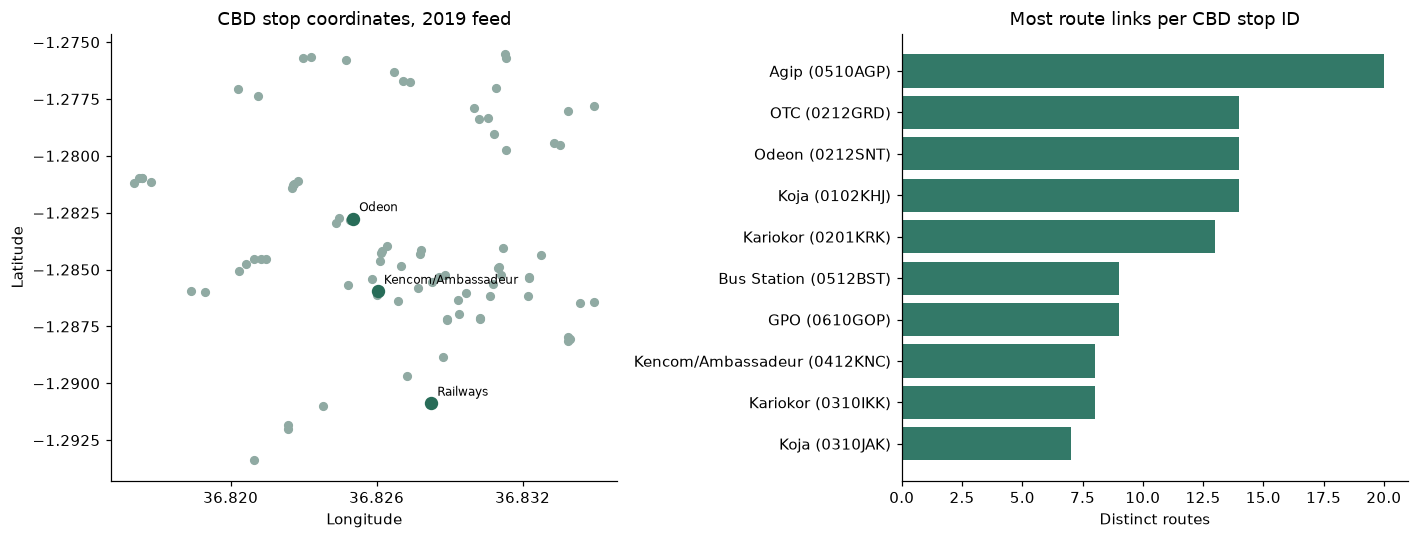

In [8]:
route_counts = network.groupby(['stop_id', 'stop_name'])['route_id'].nunique()
busiest_links = route_counts.sort_values(ascending=False).head(10)
display(busiest_links.rename('distinct routes').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(cbd['stop_lon'].to_numpy(dtype=float),
                cbd['stop_lat'].to_numpy(dtype=float), s=25, color='#90aaa3')
anchors = cbd.loc[cbd['stop_id'].isin(['0001RLW', '0004ODN', '0005AMB'])]
for row in anchors.itertuples():
    axes[0].scatter(row.stop_lon, row.stop_lat, s=60, color='#286c58')
    axes[0].annotate(row.stop_name, (row.stop_lon, row.stop_lat),
                     xytext=(4, 5), textcoords='offset points', fontsize=8)
axes[0].set(title='CBD stop coordinates, 2019 feed', xlabel='Longitude', ylabel='Latitude')
labels = [f'{name} ({stop_id})' for stop_id, name in busiest_links.index]
axes[1].barh(labels[::-1], busiest_links.to_numpy()[::-1], color='#337968')
axes[1].set(title='Most route links per CBD stop ID', xlabel='Distinct routes')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=4))
fig.tight_layout()
fig.savefig(OUT / 'network_overview.png', bbox_inches='tight')
plt.show()

## 9. Inspect the service intervals and their coverage

**Headway** means the gap between successive departures. Here, `headway_secs`
is a value recorded in the static feed. Dividing by 60 expresses it in minutes.
We count its values and check which trip templates have frequency information.
A template is a described journey pattern, not one dated observation of a bus.

Eight of the 272 trip templates have no frequency rows. We list them rather
than fill the gaps with guesses. A missing frequency row does not alone prove
the route was not operating, and a listed interval is not a measured passenger
wait. The feed omits `exact_times`, which GTFS treats as frequency-based service.

In [9]:
frequencies['headway_seconds'] = pd.to_numeric(frequencies['headway_secs'], errors='coerce')
frequencies['start_seconds'] = service_seconds(frequencies['start_time'])
frequencies['end_seconds'] = service_seconds(frequencies['end_time'])
invalid_frequency = (frequencies[['headway_seconds', 'start_seconds', 'end_seconds']].isna().any(axis=1)
                     | (frequencies['headway_seconds'] <= 0)
                     | (frequencies['end_seconds'] <= frequencies['start_seconds']))
frequency_order = frequencies.sort_values(['trip_id', 'start_seconds'])
previous_end = frequency_order.groupby('trip_id')['end_seconds'].shift()
assert not invalid_frequency.any()
assert frequencies['trip_id'].isin(trips['trip_id']).all()
assert not frequencies.duplicated(['trip_id', 'start_seconds']).any()
assert not (frequency_order['start_seconds'] < previous_end).any()
frequencies['headway_minutes'] = frequencies['headway_seconds'] / 60
missing_frequency = trips.loc[~trips['trip_id'].isin(frequencies['trip_id'])].copy()
coverage_pct = 100 * (len(trips) - len(missing_frequency)) / len(trips)
display(frequencies.groupby('headway_minutes').size().rename('frequency rows').to_frame())
print(f'Trip templates with frequency rows: {coverage_pct:.2f}%')
display(missing_frequency.merge(routes[['route_id', 'route_short_name']],
                                on='route_id', validate='many_to_one'))
assert len(missing_frequency) == 8
missing_frequency.to_csv(OUT / 'trips_without_frequency.csv', index=False)

,frequency rows
headway_minutes,
5.0,528
15.0,264


Trip templates with frequency rows: 97.06%


,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id,route_short_name
0,20101007700,DAILY,20027111,OTC,1,20027111,0027
1,20101007700,DAILY,20077110,Kariobangi,0,20077110,0027
2,20104003910,DAILY,20039110,City Cabanas,0,20039110,0039
3,20104003910,DAILY,20039111,Bypass Ruiru,1,20039111,0039
4,70805046P10,DAILY,7046P110,Kawangware,1,7046P110,046P
5,70805046P10,DAILY,7046P111,Ambassadeur,0,7046P111,046P
6,70904004810,DAILY,70048110,Yaya,0,70048110,0048
7,70904004810,DAILY,70048111,Westlands,0,70048111,0048


## 10. Group nearby boarding points with machine learning

A possible collection plan divides the study area into nearby groups so we can
review where enumerators might work. We try **K-means**, an unsupervised learning
algorithm that assigns points to groups around learned centers. This is a
notebook planning experiment, separate from the waiting-time model.

The input **features** are east/west and north/south position in approximate
kilometers. We convert degrees to comparable distance units so longitude and
latitude are not treated as equal distances by accident. This approximation
is suitable for comparing points across this small study rectangle.

We compare 2 to 5 groups. A **silhouette score** compares a point's distance
within its group with its distance to the nearest other group. Values near 1
suggest separation, near 0 suggest overlapping groups, and negative values
suggest poor assignments. The highest score here chooses a descriptive grouping;
it is not an accuracy percentage or a tested staffing plan. We fit the whole
study area because we are describing these points, not predicting unseen waits.

In [10]:
boarding = cbd.loc[cbd['location_type'].fillna('').isin(['', '0'])
                    & cbd['stop_id'].isin(links['stop_id'])].copy().reset_index(drop=True)
reference_lat = float(boarding['stop_lat'].mean())
reference_lon = float(boarding['stop_lon'].mean())
km_per_degree = np.pi * 6371.0088 / 180
features_km = np.column_stack([
    (boarding['stop_lon'].to_numpy(dtype=float) - reference_lon)
    * km_per_degree * np.cos(np.radians(reference_lat)),
    (boarding['stop_lat'].to_numpy(dtype=float) - reference_lat) * km_per_degree,
])
models, cluster_scores = {}, []
for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(features_km)
    models[k] = model
    cluster_scores.append({'groups': k,
                           'silhouette': silhouette_score(features_km, model.labels_),
                           'within_group_squared_km': model.inertia_})
cluster_scores = pd.DataFrame(cluster_scores)
display(cluster_scores.round(4))
selected_k = int(cluster_scores.loc[cluster_scores['silhouette'].idxmax(), 'groups'])
spatial_model = models[selected_k]
boarding['cluster'] = spatial_model.labels_ + 1
print(f'Boarding-point records: {len(boarding)}; selected groups: {selected_k}')
assert np.isfinite(features_km).all()
assert len(np.unique(spatial_model.labels_)) == selected_k
cluster_scores.to_csv(OUT / 'clustering_scores.csv', index=False)
joblib.dump({'model': spatial_model, 'reference_lat': reference_lat,
             'reference_lon': reference_lon, 'km_per_degree': km_per_degree,
             'input_features': ['east_km', 'north_km'], 'source_sha256': source_hash,
             'purpose': 'Offline exploratory spatial grouping'}, OUT / 'spatial_groups.joblib')

,groups,silhouette,within_group_squared_km
0,2,0.3936,24.7539
1,3,0.4652,14.5486
2,4,0.4772,10.6829
3,5,0.4236,8.3833


Boarding-point records: 77; selected groups: 4


['C:\\Users\\manot\\OneDrive\\Documents\\GitHub\\NganyaFlow\\server\\notebooks\\results\\digital-matatus-2019\\spatial_groups.joblib']

## 11. Interpret the groups

Each color marks one group of nearby boarding-point records. The group number
is just a label; group 1 is not better than group 2. The centers are averages,
not confirmed observation sites. We summarize how many points and linked routes
each group contains to support a later collection-planning discussion.

Geographic closeness does not account for walking barriers, road crossings,
passenger volumes or enumerator safety. Several platforms can sit close together,
which also affects the grouping score. Field knowledge is needed before choosing
work areas from this plot.

,boarding_point_records,linked_routes
cluster,,
1,22,39
2,33,58
3,16,16
4,6,24


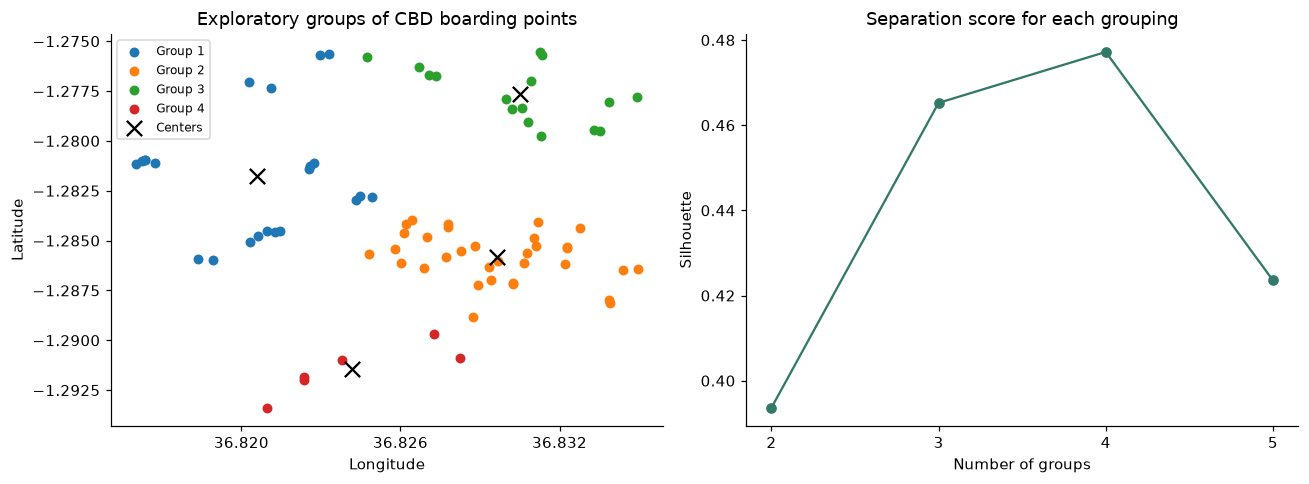

In [11]:
centers_lon = (spatial_model.cluster_centers_[:, 0]
               / (km_per_degree * np.cos(np.radians(reference_lat))) + reference_lon)
centers_lat = spatial_model.cluster_centers_[:, 1] / km_per_degree + reference_lat
point_counts = boarding.groupby('cluster').size().rename('boarding_point_records')
route_coverage = links.merge(boarding[['stop_id', 'cluster']],
                             on='stop_id', validate='many_to_one').groupby('cluster')['route_id'].nunique()
cluster_summary = pd.concat([point_counts, route_coverage.rename('linked_routes')], axis=1)
display(cluster_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, rows in boarding.groupby('cluster'):
    axes[0].scatter(rows['stop_lon'].to_numpy(dtype=float), rows['stop_lat'].to_numpy(dtype=float),
                     s=30, label=f'Group {label}')
axes[0].scatter(centers_lon, centers_lat, marker='x', s=100, color='black', label='Centers')
axes[0].set(title='Exploratory groups of CBD boarding points', xlabel='Longitude', ylabel='Latitude')
axes[0].legend(fontsize=8)
axes[1].plot(cluster_scores['groups'], cluster_scores['silhouette'], marker='o', color='#337968')
axes[1].set(title='Separation score for each grouping', xlabel='Number of groups', ylabel='Silhouette')
axes[1].set_xticks(cluster_scores['groups'])
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=4))
fig.tight_layout()
fig.savefig(OUT / 'spatial_groups.png', bbox_inches='tight')
plt.show()
boarding.to_csv(OUT / 'cbd_boarding_point_groups.csv', index=False)
cluster_summary.to_csv(OUT / 'group_summary.csv')

## 12. Demonstrate a nearby-stop search

This step connects the records to the mobile app's stage-finding workflow.
NumPy calculates the straight-line distance from a query position to each
boarding point using the Haversine formula, which accounts for Earth's curvature.
We then sort by distance. This is a calculation, not a trained model.

For a simple check, we use one boarding point's own source coordinates as the
query. Its ID should appear among the nearest zero-distance matches. Several
platforms may share a coordinate, so we do not insist on a unique first result.
This checks our search calculation, not the real-world accuracy of the source
coordinates. A walking route could be longer or inaccessible.

In [12]:
def haversine_meters(latitudes, longitudes, query_latitude, query_longitude):
    lat = np.radians(np.asarray(latitudes, dtype=float))
    lon = np.radians(np.asarray(longitudes, dtype=float))
    q_lat, q_lon = np.radians([query_latitude, query_longitude])
    a = np.sin((lat - q_lat) / 2) ** 2 + np.cos(lat) * np.cos(q_lat) * np.sin((lon - q_lon) / 2) ** 2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def nearest_stops(latitude, longitude, count=5):
    latitude, longitude = float(latitude), float(longitude)
    if not (-90 <= latitude <= 90 and -180 <= longitude <= 180):
        raise ValueError('Query coordinates are outside the allowed ranges')
    distance = haversine_meters(boarding['stop_lat'], boarding['stop_lon'], latitude, longitude)
    result = boarding[['stop_id', 'stop_name', 'stop_lat', 'stop_lon']].copy()
    result['straight_line_meters'] = distance
    return result.sort_values(['straight_line_meters', 'stop_id']).head(count)

query = boarding.loc[boarding['stop_name'].str.contains('Kencom', case=False, na=False)].iloc[0]
nearby = nearest_stops(query['stop_lat'], query['stop_lon'])
print('Example query: source coordinates of', query['stop_id'], query['stop_name'])
display(nearby.round({'straight_line_meters': 2}))
zero_distance = nearest_stops(query['stop_lat'], query['stop_lon'], count=len(boarding))
assert query['stop_id'] in set(zero_distance.loc[zero_distance['straight_line_meters'] < 1e-6, 'stop_id'])
assert nearby['straight_line_meters'].is_monotonic_increasing
# A known great-circle distance: one degree of longitude at the equator.
one_degree_meters = haversine_meters([0], [1], 0, 0)
np.testing.assert_allclose(one_degree_meters, 111195.0802, atol=0.01)
nearby.to_csv(OUT / 'nearby_stop_example.csv', index=False)

Example query: source coordinates of 0411MEB Kencom/Ambassadeur


,stop_id,stop_name,stop_lat,stop_lon,straight_line_meters
43,0411MEB,Kencom/Ambassadeur,-1.284634,36.82614,0.00
57,0512CML,Commercial,-1.284188,36.826204,50.10
56,0512CMC,Commercial,-1.283947,36.826437,83.23
51,0502AMB,Kencom/Ambassadeur,-1.2854,36.825803,93.04
9,0202LUT,Luthuli Avenue,-1.284831,36.826986,96.60


## 13. What can we say about quality and accuracy?

Data checks ask whether records pass specific rules. The silhouette score asks
whether spatial groups are separated. Prediction accuracy asks whether estimates
match independently observed answers. These measures answer different questions.

We can report the cleaning results, table-link checks, frequency coverage and
clustering score for this network. We cannot calculate a waiting-time MAE or R²
from this feed because it lacks the actual dated arrivals to compare against.
Generating arrivals from its intervals would add assumptions rather than supply
independent field answers.

For that later experiment, collect continuous arrival sessions at selected
stage/route/direction combinations across multiple days, retain time zones,
train on earlier dates, and reserve later dates for evaluation. The synthetic
waiting-time scores stay in their own notebooks.

In [13]:
quality = pd.DataFrame([
    {'measure': 'Stop records accepted by selected cleaning rules',
     'result': f'{len(stops):,} / {len(raw_stops):,}', 'meaning': 'Structural checks; not geographic truth'},
    {'measure': 'Problems in selected table-link and time-order checks',
     'result': str(int(link_checks.sum())), 'meaning': 'Rules checked in section 6'},
    {'measure': 'Trip templates with frequency rows',
     'result': f'{coverage_pct:.2f}%', 'meaning': 'Completeness of one feed component'},
    {'measure': 'Selected spatial grouping silhouette',
     'result': f'{cluster_scores["silhouette"].max():.4f}', 'meaning': 'Descriptive separation; not prediction accuracy'},
    {'measure': 'Waiting-time MAE / RMSE / R²',
     'result': 'Not available from this dataset', 'meaning': 'Requires independent, dated arrival observations'},
])
display(quality)
report = {
    'dataset_id': source['dataset_id'], 'source_sha256': source_hash,
    'source_tables': {name: len(frame) for name, frame in tables.items()},
    'accepted_stops': len(stops), 'rejected_source_stops': len(rejected_stops),
    'teaching_only_rejections': len(demo_rejected),
    'reference_and_time_problem_counts': link_checks.to_dict(),
    'trip_templates_without_frequency': len(missing_frequency),
    'frequency_trip_coverage_percent': coverage_pct,
    'cbd_stop_records': len(cbd), 'cbd_routes': len(cbd_routes),
    'cbd_boarding_points_with_route_links': len(boarding),
    'clustering': {'algorithm': 'KMeans', 'random_state': 42, 'n_init': 10,
                   'features': ['east_km', 'north_km'],
                   'selected_groups': selected_k,
                   'scores': cluster_scores.to_dict(orient='records'),
                   'purpose': 'Offline spatial grouping; no known group labels'},
    'waiting_time_mae': None, 'waiting_time_r_squared': None,
    'waiting_time_evaluation_status': 'No independent arrival labels in static network feed',
    'source_archive_unchanged': hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == source_hash,
    'software': {name: metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn']},
}
assert report['source_archive_unchanged']
(OUT / 'real_network_evaluation.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
quality.to_csv(OUT / 'quality_and_evaluation_summary.csv', index=False)
print('All notebook checks passed. Local results saved to:', OUT)

,measure,result,meaning
0,Stop records accepted by selected cleaning rules,"4,284 / 4,284",Structural checks; not geographic truth
1,Problems in selected table-link and time-order...,0,Rules checked in section 6
2,Trip templates with frequency rows,97.06%,Completeness of one feed component
3,Selected spatial grouping silhouette,0.4772,Descriptive separation; not prediction accuracy
4,Waiting-time MAE / RMSE / R²,Not available from this dataset,"Requires independent, dated arrival observations"


All notebook checks passed. Local results saved to: C:\Users\manot\OneDrive\Documents\GitHub\NganyaFlow\server\notebooks\results\digital-matatus-2019


## Findings for NganyaFlow

The archive contains 4,284 stop records, 136 routes and 272 trip templates.
All source stop records pass the selected cleaning rules. The CBD study rectangle
contains 85 stop records linked to 93 routes. Eight trip templates lack frequency
rows, a gap we preserve in the audit.

These records support historical stage browsing, route lookup and a demonstration
of nearest-stop ranking. The clustering experiment gives a way to discuss nearby
collection areas; it needs field review before guiding enumerator work. Current
route operation and real waiting-time performance require new observations.

For a presentation, use the source inventory, cleaning audit, CBD network plot,
missing-frequency table, clustering comparison and final evaluation summary.
Keep the source year visible when presenting this network.

References: [official download page](https://www.digitalmatatus.com/map.html),
[collection methodology](https://www.digitalmatatus.com/about.html),
[GTFS schedule reference](https://gtfs.org/documentation/schedule/reference/),
[scikit-learn K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html),
[silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).